## LG Aimers 9기 — 투구 제구 성공 확률 예측 · EDA

**대회**: [DACON 236743](https://dacon.io/competitions/official/236743/overview/description) · LG AI연구원 주최

| 항목 | 내용 |
|---|---|
| 과제 | 투구 직전 정보만으로 해당 투구의 **제구 성공 확률** 예측 (이진 분류의 확률 출력) |
| 평가 | `Score = max(0, 100000 × (1 − Brier / (r(1−r))))` — **Brier Skill Score** |
| 학습 | `train.csv` 1,475,092행 × 49컬럼 |
| 평가 | `test.csv` 245,789행 (비공개), 48컬럼 |
| 보조 | `trackman_history.csv` 1,793,078행 (2019~2024 Trackman 로그) |
| 제출 | `submit.zip` 코드 제출 · 추론 ≤ 10분 · 6 vCPU / 28GB RAM / L4 GPU |

**제구 실패의 정의**: ① 스트라이크존 중앙 부근 ② 존에서 크게 벗어난 공 ③ 포수 요구 방향과 반대. 그 외는 성공.

#### 이 EDA에서 답하려는 질문
1. 평가지표(BSS) 상 **베이스라인 점수는 몇 점**이고, 개선 여지는 어디에 있는가
2. train(2019~2024) → test(2025)의 **분포 이동(distribution shift)** 은 얼마나 심한가
3. `asof_*` 피처는 얼마나 강한 신호인가, **cold-start** 결측은 어떻게 다뤄야 하는가
4. 상황 변수(볼카운트·주자·이닝·LI)가 제구에 주는 영향의 크기
5. `trackman_history.csv`를 **어떤 키로 붙일 수 있는가** (붙일 수는 있는가)
6. 주최측 **베이스라인은 어디가 열려 있는가**
7. 위 결과로부터 도출되는 **검증(CV) 전략**

### 0. 환경 설정

In [ ]:
import warnings, json, os
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# 한글 폰트 (macOS)
for _f in ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Malgun Gothic"]:
    if any(_f == f.name for f in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = _f
        break
mpl.rcParams["axes.unicode_minus"] = False

# 차트 공통 스타일: 얇은 마크, 후퇴하는 그리드/축, 텍스트는 텍스트 색
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"
INK_2     = "#52514e"
MUTED     = "#898781"
GRID      = "#e1e0d9"
AXIS      = "#c3c2b7"
# 카테고리 팔레트 (검증된 참조 팔레트의 1~3번 슬롯: all-pairs CVD 안전)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
# 순차(magnitude) 램프: 단일 색상 blue, light -> dark
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.linewidth": 1.0,
    "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelsize": 10, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0, "lines.markersize": 8,
})

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
except ImportError:
    pass

_candidates = [
    Path.cwd(), Path.cwd().parent,
    Path("/content/Aimers_9th"),
    Path("/content/drive/MyDrive/LG_aimers_9th"),
    Path("/content/drive/MyDrive/Aimers_9th"),
]
PROJECT_ROOT = next((p.resolve() for p in _candidates if (p / "data/train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("data/train.csv를 찾지 못했습니다. 저장소 루트나 notebooks 폴더에서 실행하세요.")
DATA = PROJECT_ROOT / "data"
ID_COL, TARGET = "row_id", "control_success"
print("setup ok |", mpl.rcParams["font.family"])

setup ok | ['AppleGothic']


### 1. 평가지표 (Brier Skill Score) 구현

$$\text{Score} = \max\left(0,\ 100000 \times \left(1 - \frac{\text{BS}}{r(1-r)}\right)\right),\quad
\text{BS} = \frac{1}{N}\sum_i (p_i - y_i)^2,\quad r = \bar{y}$$

핵심 성질 두 가지:

- **분모 $r(1-r)$ 는 평가 데이터 자신의 평균 성공률로 계산된다.** 즉 "전체 평균을 그대로 찍는 모델"이 정확히 **0점**이다. 점수는 전부 *평균 대비 초과 성능*이다.
- 100000 배율 때문에 **BSS 0.001(=0.1%p) 이 100점**이다. 리더보드 커트라인 549.51점 ≈ **BSS 0.0055** 수준. 즉 이 문제는 애초에 신호가 매우 약하고, 소수점 넷째 자리 싸움이다.

In [2]:
def brier(y, p):
    y = np.asarray(y, dtype=float); p = np.asarray(p, dtype=float)
    return float(np.mean((p - y) ** 2))

def bss_raw(y, p):
    """클리핑 전 원점수. 음수면 '평균으로 찍는 것보다 나쁘다'는 뜻이라 진단에 유용."""
    y = np.asarray(y, dtype=float)
    r = y.mean()
    return 100000.0 * (1.0 - brier(y, p) / (r * (1.0 - r)))

def bss_score(y, p):
    """대회 공식 점수. 분모는 평가셋 자신의 평균 성공률로 계산된다."""
    return max(0.0, bss_raw(y, p))

# 감각 잡기: BSS 개선폭 -> 점수
for d in [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.02]:
    print(f"BSS {d:.4f} ({d*100:.2f}%p)  ->  {d*100000:>8,.0f} 점")
print("\n리더보드 Phase2 커트라인 549.51점 = BSS", round(549.51/100000, 6))

BSS 0.0001 (0.01%p)  ->        10 점
BSS 0.0005 (0.05%p)  ->        50 점
BSS 0.0010 (0.10%p)  ->       100 점
BSS 0.0050 (0.50%p)  ->       500 점
BSS 0.0100 (1.00%p)  ->     1,000 점
BSS 0.0200 (2.00%p)  ->     2,000 점

리더보드 Phase2 커트라인 549.51점 = BSS 0.005495


### 2. 데이터 로드

In [3]:
train = pd.read_csv(DATA / "train.csv", encoding="utf-8-sig")
test  = pd.read_csv(DATA / "test.csv",  encoding="utf-8-sig")
sub   = pd.read_csv(DATA / "sample_submission.csv", encoding="utf-8-sig")

print(f"train : {train.shape}")
print(f"test  : {test.shape}   (배포본은 형식 확인용 5건, 실제 평가 245,789건)")
print(f"sub   : {sub.shape}  columns={list(sub.columns)}")

FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
print(f"\n입력 피처 {len(FEATURES)}개 | train-test 컬럼 일치:",
      set(FEATURES) == set(test.columns) - {ID_COL})

train : (1475092, 49)
test  : (5, 48)   (배포본은 형식 확인용 5건, 실제 평가 245,789건)
sub   : (5, 2)  columns=['row_id', 'control_success']

입력 피처 47개 | train-test 컬럼 일치: True


#### 2.1 컬럼 인벤토리

`data_description.md` 기준 5개 그룹으로 나눠서 본다.

In [4]:
GROUPS = {
    "경기 기본":   ["season","game_month","game_dayofweek","inning","top_bottom","game_type"],
    "카운트/점수": ["balls_before","strikes_before","outs_before","run_top_before","run_bot_before",
                  "run_total_before","score_diff_home","score_diff_pitcher_team"],
    "주자/중요도": ["runner_on_1b","runner_on_2b","runner_on_3b","num_runners_on","base_state",
                  "home_win_expectancy","away_win_expectancy","li"],
    "선수/팀":    ["pitcher_id","batter_id","pitcher_hand","batter_hand","pitcher_team_id","batter_team_id"],
    "asof 이력":  [c for c in train.columns if c.startswith("asof_")],
}
rows = []
for g, cols in GROUPS.items():
    for c in cols:
        rows.append({"group": g, "column": c, "dtype": str(train[c].dtype),
                     "nunique": train[c].nunique(),
                     "na_rate": train[c].isna().mean(),
                     "min": train[c].min() if train[c].dtype.kind in "if" else "",
                     "max": train[c].max() if train[c].dtype.kind in "if" else ""})
inv = pd.DataFrame(rows)
print("그룹별 컬럼 수:", inv.groupby("group", sort=False).size().to_dict())
inv

그룹별 컬럼 수: {'경기 기본': 6, '카운트/점수': 8, '주자/중요도': 8, '선수/팀': 6, 'asof 이력': 19}


,group,column,dtype,nunique,na_rate,min,max
0,경기 기본,season,int64,6,0.0000,2019,2024
1,경기 기본,game_month,int64,8,0.0000,3,10
2,경기 기본,game_dayofweek,int64,7,0.0000,0,6
3,경기 기본,inning,int64,13,0.0000,1,13
4,경기 기본,top_bottom,object,2,0.0000,,
5,경기 기본,game_type,object,2,0.0000,,
6,카운트/점수,balls_before,int64,4,0.0000,0,3
7,카운트/점수,strikes_before,int64,3,0.0000,0,2
8,카운트/점수,outs_before,int64,3,0.0000,0,2
9,카운트/점수,run_top_before,int64,30,0.0000,0,30


#### 2.2 기본 무결성 검사

모델링 전에 ID·타깃·파생 컬럼의 기본 관계를 확인한다. 아래 항목이 실패하면 EDA보다 데이터 로딩/전처리를 먼저 점검해야 한다.

In [5]:
ratio_cols = [c for c in FEATURES if c.endswith("_rate")]
num_cols_all = train.select_dtypes(include=np.number).columns
ratio_ok = all(train[c].dropna().between(0, 1).all() for c in ratio_cols)
checks = [
    ("train row_id 고유", train[ID_COL].is_unique),
    ("test row_id 고유", test[ID_COL].is_unique),
    ("train/test row_id 불일치", len(set(train[ID_COL]) & set(test[ID_COL])) == 0),
    ("sample_submission ID/순서 일치", sub[ID_COL].equals(test[ID_COL])),
    ("타깃이 {0, 1}", set(train[TARGET].unique()) <= {0, 1}),
    ("run_total = top + bottom",
     (train.run_total_before == train.run_top_before + train.run_bot_before).all()),
    ("num_runners = 1B + 2B + 3B",
     (train.num_runners_on == train.runner_on_1b + train.runner_on_2b + train.runner_on_3b).all()),
    ("home/away win expectancy 합≈100",
     np.allclose(train.home_win_expectancy + train.away_win_expectancy, 100.0, atol=0.11)),
    ("비율 피처가 [0, 1]", ratio_ok),
    ("수치 피처에 ±inf 없음", np.isinf(train[num_cols_all].to_numpy()).sum() == 0),
]
quality = pd.DataFrame(checks, columns=["검사", "통과"])
quality

,검사,통과
0,train row_id 고유,True
1,test row_id 고유,True
2,train/test row_id 불일치,True
3,sample_submission ID/순서 일치,True
4,"타깃이 {0, 1}",True
5,run_total = top + bottom,True
6,num_runners = 1B + 2B + 3B,True
7,home/away win expectancy 합≈100,True
8,"비율 피처가 [0, 1]",True
9,수치 피처에 ±inf 없음,True


### 3. 가장 중요한 구조: train과 test는 **시간으로 분리**되어 있다

`train.season` 은 2019~2024, `test.season` 은 **2025**. 랜덤 분할이 아니라 **미래 예측(temporal holdout)** 이다.
단, `row_id`는 문자열 기준으로 증가하지만 실제 시간 순서를 보장하는 키가 아니다. 시즌 안에서 월이 되돌아가는 구간이 있으므로 CV는 `season`으로 나누고 `row_id` 순서 분할은 사용하지 않는다.

In [6]:
print("train seasons:", sorted(train.season.unique()))
print("test  seasons:", sorted(test.season.unique()))
print("row_id 문자열 기준 단조 증가:", train[ID_COL].is_monotonic_increasing)
season_month = train.season * 12 + train.game_month
print("현재 행의 season/month가 직전 행보다 과거인 구간:", int(season_month.diff().lt(0).sum()))
print("→ row_id는 식별자일 뿐 시간 정렬 키로 사용하지 않는다.")

by_season = train.groupby("season").agg(
    n_pitches=(TARGET, "size"),
    success_rate=(TARGET, "mean"),
    n_pitchers=("pitcher_id", "nunique"),
).reset_index()
by_season["baseline_brier"] = by_season.success_rate * (1 - by_season.success_rate)
by_season

train seasons: [2019, 2020, 2021, 2022, 2023, 2024]
test  seasons: [2025]
row_id 문자열 기준 단조 증가: True
현재 행의 season/month가 직전 행보다 과거인 구간: 6
→ row_id는 식별자일 뿐 시간 정렬 키로 사용하지 않는다.


,season,n_pitches,success_rate,n_pitchers,baseline_brier
0,2019,237413,0.5647,355,0.2458
1,2020,244087,0.5327,356,0.2489
2,2021,247088,0.5328,386,0.2489
3,2022,247472,0.5289,390,0.2492
4,2023,245525,0.5000,382,0.2500
5,2024,253507,0.4861,391,0.2498


#### 3.1 타깃의 시계열 드리프트 — 성공률이 매 시즌 떨어진다

이게 이 대회의 **1순위 리스크**다. 2019년 56.5% → 2024년 48.6%로 6시즌간 **약 8%p 하락**했다(2020→2021은 사실상 보합).
test는 2025년이므로 train 전체 평균(52.4%)을 그대로 기준 확률로 쓰는 것은 위험하다. 다만 2025의 실제 base rate는 알 수 없으므로 과거 추세만으로 단정하거나 test 예측 전체 평균을 사후 이동해서는 안 된다.

findfont: Failed to find font weight bold, now using 400.


findfont: Failed to find font weight bold, now using 400.


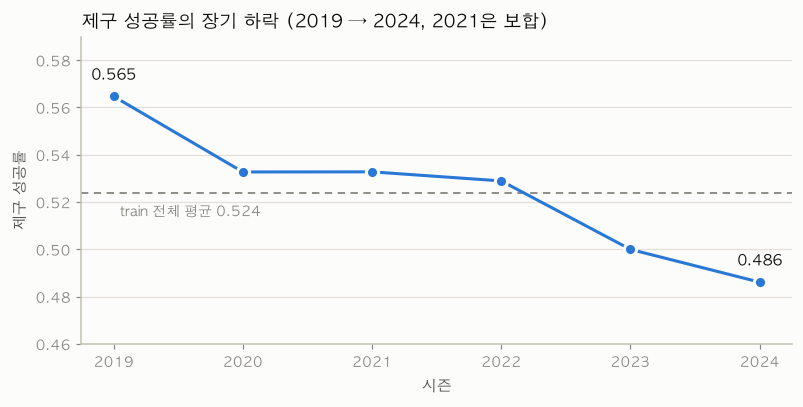

시즌간 변화폭: 0.0786
최근 3시즌(2022~2024) 평균 성공률: 0.5049
2024 단독 성공률                 : 0.4861



정규경기(game_type=R)만 봐도 하락하는가:
{2019: 0.5495, 2020: 0.5269, 2021: 0.5128, 2022: 0.5037, 2023: 0.5031, 2024: 0.4897}
R 단독 변화폭: 0.0598 → 구성비 효과가 아니라 실제 드리프트


In [7]:
fig, ax = plt.subplots(figsize=(7.4, 3.8))
x, y = by_season.season.values, by_season.success_rate.values

ax.plot(x, y, color=C1, marker="o", markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
ax.axhline(train[TARGET].mean(), color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.annotate(f"train 전체 평균 {train[TARGET].mean():.3f}", xy=(2019.05, train[TARGET].mean()),
            xytext=(0, -7), textcoords="offset points", color=MUTED, fontsize=9, va="top")

# 선택적 직접 라벨: 양 끝점만
for xi, yi in [(x[0], y[0]), (x[-1], y[-1])]:
    ax.annotate(f"{yi:.3f}", xy=(xi, yi), xytext=(0, 11), textcoords="offset points",
                ha="center", fontsize=10, color=INK, fontweight="bold")

ax.set_title("제구 성공률의 장기 하락 (2019 → 2024, 2021은 보합)")
ax.set_xlabel("시즌"); ax.set_ylabel("제구 성공률")
ax.set_ylim(0.46, 0.59); ax.set_xticks(x)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("시즌간 변화폭:", round(by_season.success_rate.max() - by_season.success_rate.min(), 4))
print("최근 3시즌(2022~2024) 평균 성공률:",
      round(train.loc[train.season >= 2022, TARGET].mean(), 4))
print("2024 단독 성공률                 :", round(train.loc[train.season == 2024, TARGET].mean(), 4))

# 이 하락이 경기 유형 구성비 변화 때문인지 확인 (§5.3에서 game_type을 자세히 본다)
r_only = train[train.game_type == "R"].groupby("season")[TARGET].mean()
print("\n정규경기(game_type=R)만 봐도 하락하는가:")
print(r_only.round(4).to_dict())
print("R 단독 변화폭:", round(r_only.max() - r_only.min(), 4), "→ 구성비 효과가 아니라 실제 드리프트")

#### 3.2 드리프트가 점수에 미치는 영향 — 2024를 test 대용으로 실험

"train 전체 평균으로 찍기" vs "직전 시즌 평균으로 찍기"를 2024년 홀드아웃에서 비교한다.
분모는 **홀드아웃 자신의** $r(1-r)$ 로 계산되므로, 상수 예측이라도 **어떤 상수냐**에 따라 점수가 갈린다.

In [8]:
hold = train[train.season == 2024]
prev = train[train.season < 2024]
y_hold = hold[TARGET].values

cands = {
    "train 전체(2019-23) 평균": prev[TARGET].mean(),
    "직전 1시즌(2023) 평균":    train.loc[train.season == 2023, TARGET].mean(),
    "직전 3시즌(2021-23) 평균": train.loc[train.season.between(2021, 2023), TARGET].mean(),
    "0.5 고정":                 0.5,
    "홀드아웃 실제 평균(상한)": y_hold.mean(),
}
res = pd.DataFrame([
    {"전략": k, "예측 상수": v,
     "Brier": brier(y_hold, np.full_like(y_hold, v, dtype=float)),
     "원점수(클리핑 전)": bss_raw(y_hold, np.full_like(y_hold, v, dtype=float)),
     "대회 점수": bss_score(y_hold, np.full_like(y_hold, v, dtype=float))}
    for k, v in cands.items()])
res

,전략,예측 상수,Brier,원점수(클리핑 전),대회 점수
0,train 전체(2019-23) 평균,0.5316,0.2519,-827.8875,0.0000
1,직전 1시즌(2023) 평균,0.5000,0.2500,-76.8140,0.0000
2,직전 3시즌(2021-23) 평균,0.5206,0.2510,-476.1735,0.0000
3,0.5 고정,0.5000,0.2500,-77.2890,0.0000
4,홀드아웃 실제 평균(상한),0.4861,0.2498,-0.0000,0.0000


**해석**: 상수 예측은 최선(홀드아웃 실제 평균)이라도 정확히 **0점**이다 — 지표 정의상 그게 원점이기 때문.
그런데 **원점수 열을 보면 상수를 잘못 고를 때의 손실이 드러난다.** train 전체 평균(0.5316)을 그대로 쓰면
2024년 실제 평균(0.4861)보다 4.5%p 높아 원점수가 **음수**가 된다.

즉 드리프트는 이렇게 점수를 깎는다: **모델이 학습한 절대 확률 수준이 통째로 어긋난다.**
→ 최근 시즌 가중 학습 + 2025 base rate 기준 확률 재보정이 선택이 아니라 필수다.

### 4. 결측 구조 — cold-start 문제

`asof_*` 는 "이 투구 직전까지의 누적 기록"이므로, **표본이 0이면 결측**이다.
즉 결측 자체가 "신인/시즌 첫 등판/첫 타석"이라는 **정보를 담은 결측**이다. 단순 평균 대치는 이 신호를 지운다.

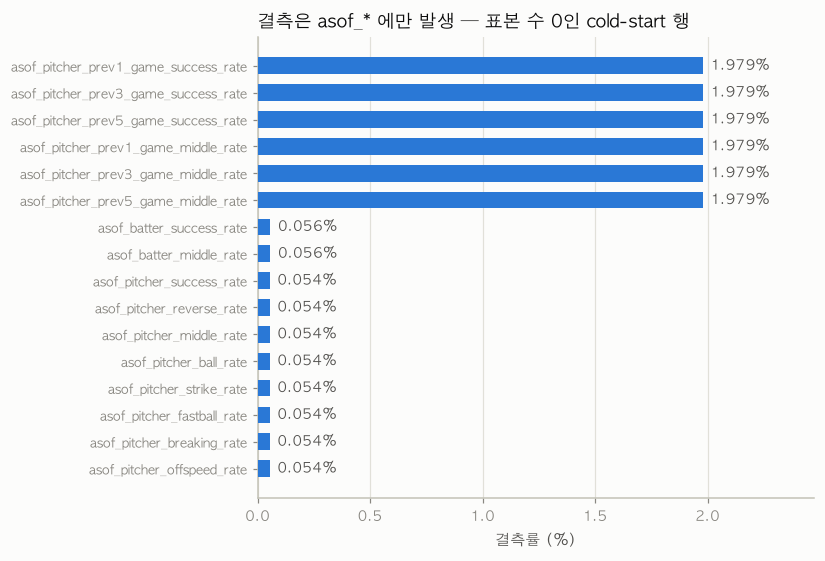

결측 있는 컬럼 수: 16 / 49


In [9]:
na = train.isna().mean()
na = na[na > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.6, 5.2))
ypos = np.arange(len(na))[::-1]
ax.barh(ypos, na.values * 100, height=0.62, color=C1, zorder=3)
for yp, v in zip(ypos, na.values * 100):
    ax.annotate(f"{v:.3f}%", xy=(v, yp), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_yticks(ypos); ax.set_yticklabels(na.index, fontsize=8.5)
ax.set_xlabel("결측률 (%)"); ax.set_xlim(0, na.max() * 100 * 1.25)
ax.set_title("결측은 asof_* 에만 발생 — 표본 수 0인 cold-start 행")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("결측 있는 컬럼 수:", len(na), "/", train.shape[1])

In [10]:
# 결측 자체가 신호인가? 결측 여부별 실제 성공률 비교
chk = []
for c, n_col in [("asof_pitcher_success_rate", "asof_pitcher_n"),
                 ("asof_batter_success_rate",  "asof_batter_n"),
                 ("asof_pitcher_prev1_game_success_rate", None),
                 ("asof_pitcher_prev5_game_success_rate", None)]:
    m = train[c].isna()
    chk.append({"컬럼": c, "결측 행수": int(m.sum()), "결측률": m.mean(),
                "결측 시 성공률": train.loc[m, TARGET].mean(),
                "비결측 시 성공률": train.loc[~m, TARGET].mean()})
cold = pd.DataFrame(chk)
cold["차이(%p)"] = (cold["결측 시 성공률"] - cold["비결측 시 성공률"]) * 100
cold

,컬럼,결측 행수,결측률,결측 시 성공률,비결측 시 성공률,차이(%p)
0,asof_pitcher_success_rate,792,0.0005,0.5518,0.5238,2.8017
1,asof_batter_success_rate,830,0.0006,0.6024,0.5237,7.8688
2,asof_pitcher_prev1_game_success_rate,29185,0.0198,0.5508,0.5232,2.7611
3,asof_pitcher_prev5_game_success_rate,29185,0.0198,0.5508,0.5232,2.7611


`asof_pitcher_n == 0` (커리어 첫 투구)인 행은 개수는 적지만 성공률이 뚜렷이 다르다.
→ **`is_cold_start` 플래그를 명시 피처로 만들고**, 결측은 트리 모델의 native NaN 처리(LightGBM/XGBoost/CatBoost)에 맡기는 것이 안전하다.

#### 4.1 다음 시즌의 미관측 선수 비율

2024를 test 대용으로 두고 2019~2023에 없던 선수의 행 비율을 확인한다. raw 선수 ID에 과도하게 의존하면 이 구간에서 일반화가 무너질 수 있다.

In [11]:
past, future = train[train.season < 2024], train[train.season == 2024]
unseen_rows = []
for col in ["pitcher_id", "batter_id"]:
    unseen = ~future[col].isin(past[col].unique())
    unseen_rows.append({
        "ID": col,
        "미관측 행수": int(unseen.sum()),
        "미관측 행 비율": unseen.mean(),
        "미관측 고유 ID 수": future.loc[unseen, col].nunique(),
    })
unseen_2024 = pd.DataFrame(unseen_rows)
unseen_2024

,ID,미관측 행수,미관측 행 비율,미관측 고유 ID 수
0,pitcher_id,50348,0.1986,81
1,batter_id,23588,0.0930,88


### 5. 상황 변수와 제구 성공률

각 변수를 단독으로 봤을 때 성공률이 얼마나 흔들리는지 = 그 변수가 가진 **raw 신호의 크기**.
전체 평균 52.38% 대비 편차로 읽는다.

#### 5.1 볼카운트 — 가장 강한 상황 신호

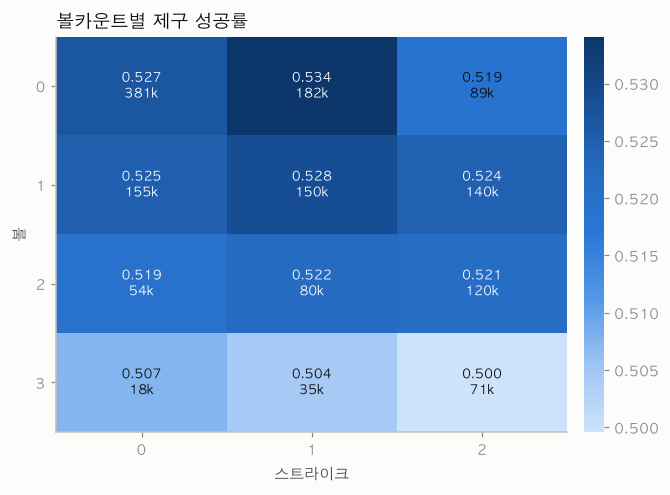

성공률 최대-최소 폭: 3.5%p   (전체 평균 52.4%)

가장 높은 5개 카운트
   balls_before  strikes_before   rate       n
1             0               1 0.5341  181775
4             1               1 0.5285  150304
0             0               0 0.5266  380996
3             1               0 0.5249  154878
5             1               2 0.5244  139598

가장 낮은 5개 카운트
    balls_before  strikes_before   rate      n
11             3               2 0.4996  70538
10             3               1 0.5044  35425
9              3               0 0.5073  18060
2              0               2 0.5185  89281
6              2               0 0.5189  54187


In [12]:
cnt = (train.groupby(["balls_before", "strikes_before"])
             .agg(rate=(TARGET, "mean"), n=(TARGET, "size")).reset_index())
grid_rate = cnt.pivot(index="balls_before", columns="strikes_before", values="rate")
grid_n    = cnt.pivot(index="balls_before", columns="strikes_before", values="n")

fig, ax = plt.subplots(figsize=(6.2, 4.6))
im = ax.imshow(grid_rate.values, cmap=SEQ, aspect="auto",
               vmin=np.nanmin(grid_rate.values), vmax=np.nanmax(grid_rate.values))
ax.set_xticks(range(grid_rate.shape[1])); ax.set_xticklabels(grid_rate.columns)
ax.set_yticks(range(grid_rate.shape[0])); ax.set_yticklabels(grid_rate.index)
ax.set_xlabel("스트라이크"); ax.set_ylabel("볼")
ax.set_title("볼카운트별 제구 성공률")
ax.grid(False)

# 셀 값 직접 라벨 (배경 밝기에 따라 잉크 색 전환)
lo, hi = np.nanmin(grid_rate.values), np.nanmax(grid_rate.values)
for i in range(grid_rate.shape[0]):
    for j in range(grid_rate.shape[1]):
        v, nn = grid_rate.values[i, j], grid_n.values[i, j]
        if np.isnan(v): continue
        ax.text(j, i, f"{v:.3f}\n{nn/1000:.0f}k", ha="center", va="center", fontsize=8.5,
                color="#ffffff" if (v - lo) / (hi - lo) > 0.55 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cb.outline.set_visible(False); cb.ax.tick_params(color=MUTED, labelcolor=MUTED)
plt.tight_layout(); plt.show()

print(f"성공률 최대-최소 폭: {(hi-lo)*100:.1f}%p   (전체 평균 {train[TARGET].mean()*100:.1f}%)")
print("\n가장 높은 5개 카운트");  print(cnt.nlargest(5, "rate")[["balls_before","strikes_before","rate","n"]])
print("\n가장 낮은 5개 카운트");  print(cnt.nsmallest(5, "rate")[["balls_before","strikes_before","rate","n"]])

읽히는 패턴은 **볼이 쌓일수록 성공률이 떨어진다**는 것이다 (3-2가 최저 0.4996, 3-0/3-1도 하위권).
투수가 몰리면 스트라이크를 넣어야 해서 존 가운데로 향하고, 그게 정의상 **제구 실패**로 집계된다.

주의할 점은 스트라이크 쪽은 단조가 아니라는 것이다 — 최고는 0-2가 아니라 **0-1(0.5341)** 이고,
0-2는 오히려 평균 아래(0.5185)다. 2스트라이크에서는 크게 빼는 유인구가 많아지는데,
"존에서 크게 벗어난 공"도 실패로 집계되기 때문에 상쇄된다.

→ 단순 `balls − strikes` 하나로는 이 비단조성을 담지 못한다. **카운트 12종을 범주형으로** 넣거나
`balls`, `strikes`를 각각 남기고 트리가 상호작용을 잡게 하는 편이 낫다.

#### 5.2 나머지 상황 변수 — 신호 크기 한눈에 비교

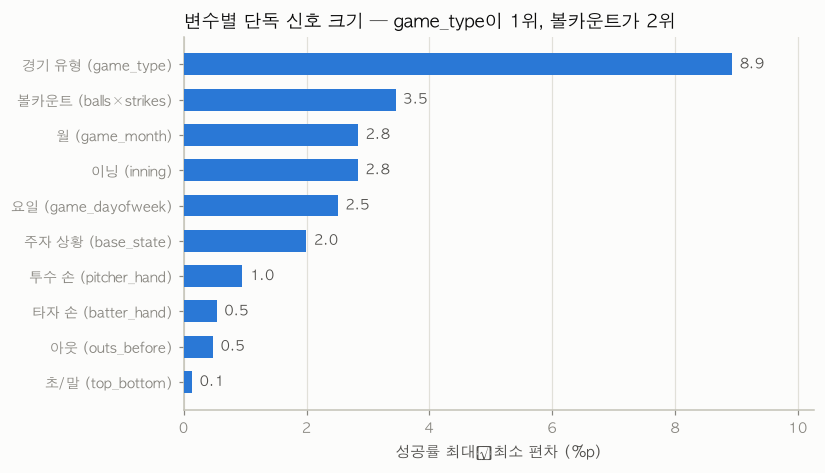

,변수,구간 수,최소,최대,편차(%p)
8,경기 유형 (game_type),2,0.5140,0.6033,8.9246
9,볼카운트 (balls×strikes),12,0.4996,0.5341,3.4502
6,월 (game_month),8,0.5092,0.5375,2.8335
2,이닝 (inning),11,0.5038,0.5321,2.8311
7,요일 (game_dayofweek),7,0.4997,0.5247,2.5047
0,주자 상황 (base_state),8,0.5161,0.5361,1.9924
4,투수 손 (pitcher_hand),2,0.5167,0.5262,0.9523
5,타자 손 (batter_hand),2,0.5209,0.5263,0.5350
1,아웃 (outs_before),3,0.5214,0.5261,0.4740
3,초/말 (top_bottom),2,0.5231,0.5244,0.1327


In [13]:
def rate_by(col, min_n=3000):
    g = train.groupby(col).agg(rate=(TARGET, "mean"), n=(TARGET, "size"))
    return g[g.n >= min_n]

TARGETS_CAT = [("base_state", "주자 상황"), ("outs_before", "아웃"), ("inning", "이닝"),
               ("top_bottom", "초/말"), ("pitcher_hand", "투수 손"), ("batter_hand", "타자 손"),
               ("game_month", "월"), ("game_dayofweek", "요일"), ("game_type", "경기 유형")]

spread = []
for c, ko in TARGETS_CAT:
    g = rate_by(c)
    spread.append({"변수": f"{ko} ({c})", "구간 수": len(g),
                   "최소": g.rate.min(), "최대": g.rate.max(),
                   "편차(%p)": (g.rate.max() - g.rate.min()) * 100})
# 볼카운트도 같은 척도로 추가
spread.append({"변수": "볼카운트 (balls×strikes)", "구간 수": len(cnt),
               "최소": cnt.rate.min(), "최대": cnt.rate.max(),
               "편차(%p)": (cnt.rate.max() - cnt.rate.min()) * 100})
spread = pd.DataFrame(spread).sort_values("편차(%p)", ascending=False)

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ypos = np.arange(len(spread))[::-1]
ax.barh(ypos, spread["편차(%p)"], height=0.62, color=C1, zorder=3)
for yp, v in zip(ypos, spread["편차(%p)"]):
    ax.annotate(f"{v:.1f}", xy=(v, yp), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set_yticks(ypos); ax.set_yticklabels(spread["변수"], fontsize=9)
ax.set_xlabel("성공률 최대−최소 편차 (%p)")
ax.set_title("변수별 단독 신호 크기 — game_type이 1위, 볼카운트가 2위")
ax.set_xlim(0, spread["편차(%p)"].max() * 1.15)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
spread

#### 5.3 🚨 `game_type` — 가장 큰 편차이자 가장 큰 함정

편차 8.9%p로 1위인데, **이건 예측에 쓸 신호가 아니라 데이터를 걸러야 할 이유**일 가능성이 크다.

  game_type        n   rate  pitchers     비중
0         F   161004 0.6033       633 0.1091
1         R  1314088 0.5140       612 0.8909 



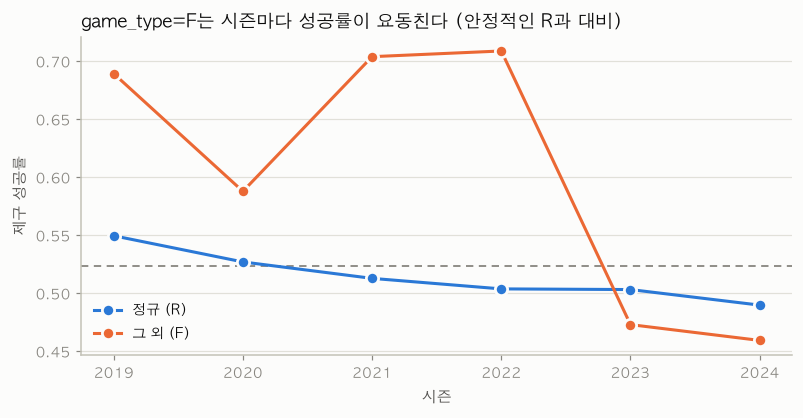

F 시즌별 변동폭: 0.2495
R 시즌별 변동폭: 0.0598

배포된 test 샘플의 game_type: {'R': 5}


In [14]:
gt = train.groupby("game_type").agg(
    n=(TARGET, "size"), rate=(TARGET, "mean"), pitchers=("pitcher_id", "nunique")).reset_index()
gt["비중"] = gt.n / len(train)
print(gt, "\n")

gt_season = train.groupby(["season", "game_type"])[TARGET].mean().unstack()
gt_n      = train.groupby(["season", "game_type"]).size().unstack()

fig, ax = plt.subplots(figsize=(7.4, 3.9))
styles = {"R": (C1, "정규 (R)"), "F": (C2, "그 외 (F)")}
for g_ in ["R", "F"]:
    color, label = styles[g_]
    ax.plot(gt_season.index, gt_season[g_], color=color, marker="o",
            markeredgecolor=SURFACE, markeredgewidth=1.8, label=label, zorder=3)
ax.axhline(train[TARGET].mean(), color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.set_title("game_type=F는 시즌마다 성공률이 요동친다 (안정적인 R과 대비)")
ax.set_xlabel("시즌"); ax.set_ylabel("제구 성공률"); ax.set_xticks(gt_season.index)
ax.legend(loc="lower left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("F 시즌별 변동폭:", round(gt_season["F"].max() - gt_season["F"].min(), 4))
print("R 시즌별 변동폭:", round(gt_season["R"].max() - gt_season["R"].min(), 4))
print("\n배포된 test 샘플의 game_type:", test.game_type.value_counts().to_dict())

**진단**: `F`는 전체의 약 11%(161k행)인데 성공률이 시즌별로 0.46~0.71을 오간다. `R`은 0.49~0.55로 완만하다.
투수 수도 F가 633명으로 R(612명)보다 많다. **F의 정확한 의미는 데이터 설명만으로 확정할 수 없고**, 관측상 R과 분포가 다른 불안정한 하위 집단으로만 해석한다.

**주의**: 배포된 test 샘플 5건은 전부 `R`이지만, **5건으로 실제 평가셋 전체가 R이라고 단정할 수 없다.**
따라서 다음 두 갈래를 실험으로 결정해야 한다.
- `F`를 학습에서 제외하거나 sample weight를 낮춘다 (test가 R 중심이라는 가정)
- `game_type`을 그대로 피처로 넣고 모델이 구분하게 둔다 (test에 F가 섞여 있을 가능성 대비)

→ **2024 홀드아웃을 R만으로 평가**해서 두 방식을 비교하는 것이 가장 안전한 판단 근거다.

#### 5.4 주자 상황 · 이닝 · 상황 중요도(LI)

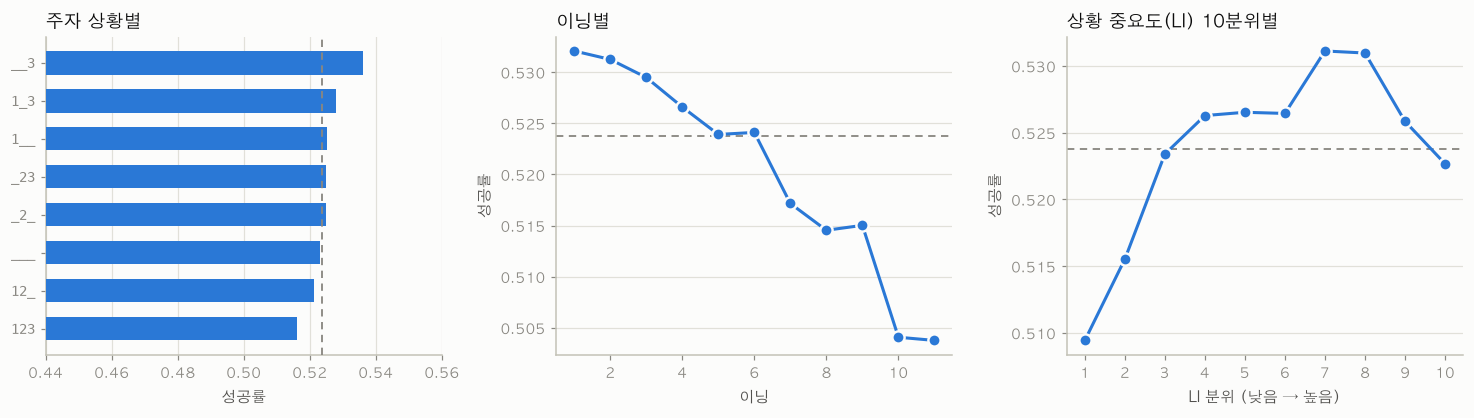

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
mean_rate = train[TARGET].mean()

# (1) 주자 상황
g = rate_by("base_state").sort_values("rate")
axes[0].barh(np.arange(len(g)), g.rate, height=0.62, color=C1, zorder=3)
axes[0].set_yticks(np.arange(len(g))); axes[0].set_yticklabels(g.index, fontfamily="monospace")
axes[0].axvline(mean_rate, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=4)
axes[0].set_xlim(0.44, 0.56); axes[0].set_title("주자 상황별"); axes[0].set_xlabel("성공률")
axes[0].grid(axis="y", visible=False)

# (2) 이닝
g = rate_by("inning")
axes[1].plot(g.index, g.rate, color=C1, marker="o", markeredgecolor=SURFACE,
             markeredgewidth=1.6, zorder=3)
axes[1].axhline(mean_rate, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
axes[1].set_title("이닝별"); axes[1].set_xlabel("이닝"); axes[1].set_ylabel("성공률")
axes[1].grid(axis="x", visible=False)

# (3) LI 10분위
li_q = pd.qcut(train.li, 10, duplicates="drop")
g = train.groupby(li_q)[TARGET].agg(["mean", "size"])
axes[2].plot(np.arange(len(g)), g["mean"], color=C1, marker="o",
             markeredgecolor=SURFACE, markeredgewidth=1.6, zorder=3)
axes[2].axhline(mean_rate, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
axes[2].set_xticks(np.arange(len(g)))
axes[2].set_xticklabels([f"{i+1}" for i in range(len(g))])
axes[2].set_title("상황 중요도(LI) 10분위별")
axes[2].set_xlabel("LI 분위 (낮음 → 높음)"); axes[2].set_ylabel("성공률")
axes[2].grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

### 6. `asof_*` 피처의 예측력

이 대회에서 **사실상 유일하게 강한 피처군**이다. 규칙상 test 내부 행으로 통계를 만들 수 없기 때문에,
주최측이 미리 계산해준 `asof_*` 가 "선수 능력"을 담은 유일한 통로다.

#### 6.1 타깃과의 상관

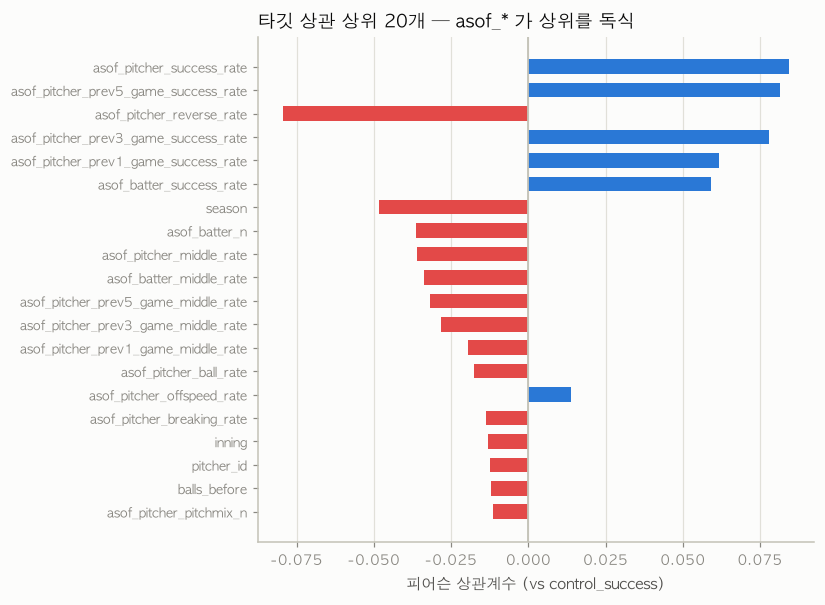

상관 |r| > 0.05 인 피처: 6 개
최대 |상관|: 0.0843
asof_pitcher_success_rate               0.0843
asof_pitcher_prev5_game_success_rate    0.0816
asof_pitcher_reverse_rate              -0.0795
asof_pitcher_prev3_game_success_rate    0.0778
asof_pitcher_prev1_game_success_rate    0.0617
asof_batter_success_rate                0.0589
season                                 -0.0483
asof_batter_n                          -0.0363
asof_pitcher_middle_rate               -0.0361
asof_batter_middle_rate                -0.0338
Name: control_success, dtype: float64


In [16]:
num_cols = [c for c in FEATURES if train[c].dtype.kind in "if"]
corr = train[num_cols + [TARGET]].corr(numeric_only=True)[TARGET].drop(TARGET)
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
top = corr.head(20)[::-1]

# 상관은 부호(polarity)를 가지므로 발산형: blue(양) / red(음), 중립은 회색 축
fig, ax = plt.subplots(figsize=(7.6, 5.6))
ypos = np.arange(len(top))
ax.barh(ypos, top.values, height=0.62,
        color=[C1 if v > 0 else "#e34948" for v in top.values], zorder=3)
ax.axvline(0, color=AXIS, lw=1.2, zorder=4)
ax.set_yticks(ypos); ax.set_yticklabels(top.index, fontsize=8.5)
ax.set_xlabel("피어슨 상관계수 (vs control_success)")
ax.set_title("타깃 상관 상위 20개 — asof_* 가 상위를 독식")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("상관 |r| > 0.05 인 피처:", (corr.abs() > 0.05).sum(), "개")
print("최대 |상관|:", round(corr.abs().max(), 4))
print(corr.head(10))

**주의: 개별 선형 신호의 크기를 보라.** 최상위 피처도 Pearson 상관이 0.084다. 이는 단일 변수의 선형 관계가 약하다는 뜻이지, 비선형 효과나 변수 간 상호작용까지 약하다는 증거는 아니다.

또한 `season` 자체가 상관 상위권(−0.048)에 올라와 있다 — §3.1의 드리프트가 그대로 잡힌 것이다.
트리 모델에서 train에 없는 2025 값은 학습된 마지막 구간으로 라우팅될 뿐 선형 추세를 외삽하지 않는다. 그렇다고 `season`이 항상 무용한 것은 아니다. 최근 레짐을 구분하는 데 기여할 수 있으므로 **시간 폴드에서 포함/제외를 비교**하고, 추세 보정 수단으로 오해하지 않는다.

#### 6.2 캘리브레이션 — `asof_pitcher_success_rate` 는 그대로 확률로 쓸 만한가

BSS는 **확률의 정확도**를 재는 지표이므로, 피처가 실제 확률과 얼마나 일치하는지(대각선에 붙는지)가 중요하다.

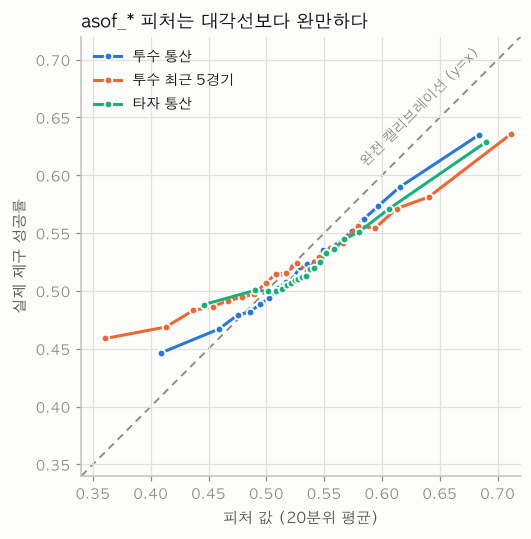

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 5.0))
specs = [("asof_pitcher_success_rate", "투수 통산", C1),
         ("asof_pitcher_prev5_game_success_rate", "투수 최근 5경기", C2),
         ("asof_batter_success_rate", "타자 통산", C3)]

for col, label, color in specs:
    d = train[[col, TARGET]].dropna()
    q = pd.qcut(d[col], 20, duplicates="drop")
    g = d.groupby(q).agg(pred=(col, "mean"), actual=(TARGET, "mean"))
    ax.plot(g.pred, g.actual, color=color, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=label, zorder=3)

lims = (0.34, 0.72)
ax.plot(lims, lims, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.annotate("완전 캘리브레이션 (y=x)", xy=(0.695, 0.695), xytext=(-6, 6),
            textcoords="offset points", ha="right", va="bottom",
            color=MUTED, fontsize=9, rotation=45, rotation_mode="anchor")
ax.set_xlim(*lims); ax.set_ylim(*lims); ax.set_aspect("equal")
ax.set_xlabel("피처 값 (20분위 평균)"); ax.set_ylabel("실제 제구 성공률")
ax.set_title("asof_* 피처는 대각선보다 완만하다")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

세 곡선 모두 **대각선보다 기울기가 완만하다.** 피처가 0.40이라고 말할 때 실제 성공률은 0.45~0.46,
0.65라고 말할 때 실제는 0.58~0.59 근처다. 즉 **피처는 실제보다 과장해서 벌어져 있다.**
§6.2의 "③ 평균+축소"가 점수를 끌어올린 이유가 이 그림에 그대로 있다.

In [18]:
# 진단 전용: 2024 정답 평균을 사용한 oracle 보정. 정직한 모델 점수가 아니다.
h = train[train.season == 2024]
rows = []
def _calibrate(p, target_mean, shrink=1.0):
    """평균을 target_mean으로 옮기고(shift), 분산을 shrink배로 줄인다(shrink)."""
    return np.clip((p - p.mean()) * shrink + target_mean, 1e-6, 1 - 1e-6)

for col, label, _ in specs:
    d = h[[col, TARGET]].dropna()
    p_raw, m = d[col].values, d[TARGET].mean()
    rows.append({
        "피처": f"{label} ({col})", "유효 행수": len(d),
        "피처 평균": p_raw.mean(), "실제 평균": m,
        "① 원본": bss_raw(d[TARGET], p_raw),
        "② oracle 평균 보정": bss_raw(d[TARGET], _calibrate(p_raw, m)),
        "③ oracle 평균+축소(0.3)": bss_raw(d[TARGET], _calibrate(p_raw, m, 0.3)),
    })
base = h[TARGET].mean()
rows.append({"피처": "상수(홀드아웃 평균)", "유효 행수": len(h), "피처 평균": base, "실제 평균": base,
             "① 원본": 0.0, "② oracle 평균 보정": 0.0, "③ oracle 평균+축소(0.3)": 0.0})
pd.DataFrame(rows)

,피처,유효 행수,피처 평균,실제 평균,① 원본,② oracle 평균 보정,③ oracle 평균+축소(0.3)
0,투수 통산 (asof_pitcher_success_rate),253426,0.5114,0.4861,-186.0363,73.4896,269.4970
1,투수 최근 5경기 (asof_pitcher_prev5_game_success_rate),249869,0.4909,0.4865,-381.0420,-373.2943,307.2494
2,타자 통산 (asof_batter_success_rate),253419,0.5175,0.4861,-862.1906,-463.8643,-20.7553
3,상수(홀드아웃 평균),253507,0.4861,0.4861,0.0000,0.0000,0.0000


#### 🚨 이 표가 이 대회의 핵심을 보여준다

세 피처 모두 **날것 그대로 제출하면 원점수가 음수** — "그냥 평균 찍기보다 나쁘다"는 뜻이다.
예측력이 없어서가 아니다 (§6.1에서 상관은 분명히 양수였다). 두 가지가 어긋나 있다.

**① 수준(level)이 어긋남** — 피처 평균은 커리어 누적이라 과거의 높은 성공률을 끌고 오는데,
2024년 실제 평균은 그보다 낮다. 아래의 평균 보정은 **검증 정답 평균을 사용한 oracle 진단**이라 실제 모델 점수가 아니다. 수준 오차의 비용을 분해해서 보는 용도다. oracle로 평균만 맞추면 세 피처 모두 크게 개선된다
(투수 통산은 −186 → **+73**으로 부호까지 뒤집힌다).

**② 퍼짐(spread)이 과함** — 평균 보정만으로 타자 통산·최근5경기는 여전히 음수다.
이 피처들은 실제 신호 대비 **과하게 벌어져 있어서**, 극단값이 Brier에 그대로 벌점으로 돌아온다.
분산을 0.3배로 줄이면(③) 투수 계열 둘은 확실히 양수가 되고(+269, +307),
타자 통산도 −862에서 −21까지 올라와 사실상 손익분기에 닿는다.
이건 §6.3에서 본 **평균회귀(기울기 0.649)** 와 같은 현상이다.

세 피처 중 **타자 통산만 끝내 양수로 못 넘어간다**는 점도 함께 읽어야 한다.
제구는 결국 투수가 만드는 결과이므로, 타자 쪽 피처는 단독 확률로는 쓸 수 없고
모델 안에서 보조 변수로만 기여할 것으로 봐야 한다.

> **결론: Brier는 판별력(resolution)과 캘리브레이션(reliability)을 함께 보상한다.**
> AUC만 높여서는 부족하고 확률의 절대 수준과 퍼짐도 시간 검증 폴드에서 맞춰야 한다.
> 이 표의 target mean과 0.3은 효과를 분해하는 oracle/시연 값이다. 실제 보정기는 이전 시간 폴드의 OOF 예측으로 학습해야 한다.

#### ⚠️ 단, "축소가 정답"이라고 일반화하면 안 된다

여기서 축소가 통한 건 **날것의 누적 비율 피처**가 표본 부족 탓에 과하게 벌어져 있었기 때문이다.
**학습된 모델은 정반대일 수 있다.** 실제로 주최측 베이스라인 RF는 과소 자신(under-dispersed) 상태라
분산을 **확대**해야 점수가 오른다 (§8에서 실측한다).

> **원칙**: 판별력과 캘리브레이션을 모두 Brier로 평가한다.
> **방향**(축소냐 확대냐)은 대상마다 다르므로 **가정하지 말고 과거 OOF에서 재라.**

#### 6.3 투수 능력은 시즌을 넘어 지속되는가

test가 2025년인 이상, **2024년까지의 투수 능력이 2025년에도 유지되는지**가 모델 일반화의 핵심이다.
2023 → 2024 시즌 간 투수별 성공률의 관계를 본다.

findfont: Failed to find font weight bold, now using 400.


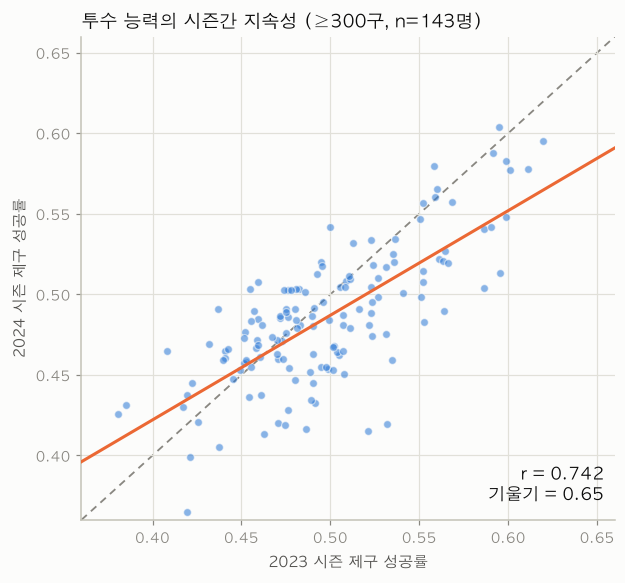

상관 r = 0.7419, 회귀 기울기 = 0.649
기울기 < 1 이면 평균회귀(regression to the mean) — 과거 성공률을 그대로 쓰면 과신하게 됨


In [19]:
MIN_P = 300
ps = (train[train.season.isin([2023, 2024])]
      .groupby(["pitcher_id", "season"])[TARGET].agg(["mean", "size"]).reset_index())
ps = ps[ps["size"] >= MIN_P]
w = ps.pivot(index="pitcher_id", columns="season", values="mean").dropna()
w.columns = ["y2023", "y2024"]
r = w.y2023.corr(w.y2024)

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(w.y2023, w.y2024, s=26, color=C1, alpha=0.55,
           edgecolor=SURFACE, linewidth=0.8, zorder=3)
lims = (0.36, 0.66)
ax.plot(lims, lims, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
b, a = np.polyfit(w.y2023, w.y2024, 1)
xs = np.linspace(*lims, 10)
ax.plot(xs, a + b * xs, color=C2, lw=2, zorder=4)
ax.annotate(f"r = {r:.3f}\n기울기 = {b:.2f}", xy=(0.98, 0.03), xycoords="axes fraction",
            ha="right", va="bottom", fontsize=11, color=INK, fontweight="bold")
ax.set_xlim(*lims); ax.set_ylim(*lims)
ax.set_xlabel("2023 시즌 제구 성공률"); ax.set_ylabel("2024 시즌 제구 성공률")
ax.set_title(f"투수 능력의 시즌간 지속성 (≥{MIN_P}구, n={len(w)}명)")
plt.tight_layout(); plt.show()

print(f"상관 r = {r:.4f}, 회귀 기울기 = {b:.3f}")
print("기울기 < 1 이면 평균회귀(regression to the mean) — 과거 성공률을 그대로 쓰면 과신하게 됨")

기울기가 1보다 작다면 **shrinkage(평균 쪽으로 당기기)** 가 필요하다는 뜻이다.
`asof_pitcher_n` 을 신뢰도 가중치로 써서 경험적 베이즈 형태로 보정하는 것이 정석이다:

$$\hat{p} = \frac{n \cdot \text{asof\_rate} + k \cdot \text{prior}}{n + k}$$

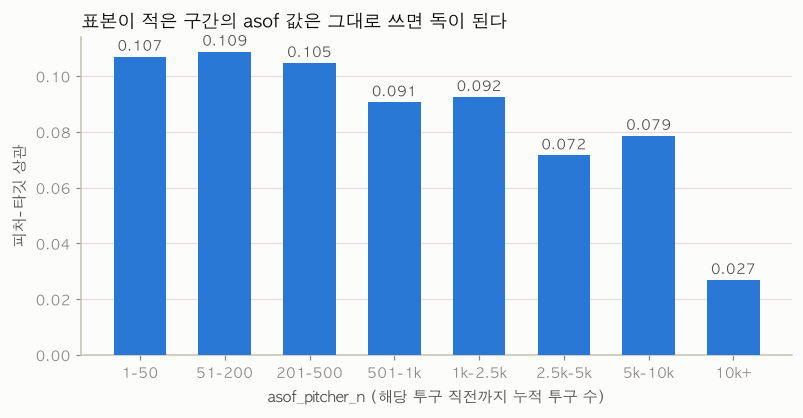

,bin,n_rows,corr,원본 원점수,oracle 평균 보정 후 원점수
0,1-50,"37,648.0000",0.1070,"-5,348.3608","-5,324.9358"
1,51-200,"94,711.0000",0.1088,658.6052,660.2585
2,201-500,"153,217.0000",0.1047,998.8782,"1,002.6052"
3,501-1k,"209,047.0000",0.0906,718.0643,746.1005
4,1k-2.5k,"413,029.0000",0.0925,799.8430,842.3808
5,2.5k-5k,"326,947.0000",0.0716,360.2625,473.4801
6,5k-10k,"201,298.0000",0.0786,421.3189,613.1277
7,10k+,"38,403.0000",0.0269,-119.3951,-66.3091


In [20]:
# 표본 수(asof_pitcher_n) 구간별로 피처의 신뢰도가 어떻게 변하는가
d = train[["asof_pitcher_n", "asof_pitcher_success_rate", TARGET]].dropna()
bins = [0, 50, 200, 500, 1000, 2500, 5000, 10000, np.inf]
labels = ["1-50", "51-200", "201-500", "501-1k", "1k-2.5k", "2.5k-5k", "5k-10k", "10k+"]
d["bin"] = pd.cut(d.asof_pitcher_n, bins=bins, labels=labels, right=True)
def _bin_stats(x):
    p = x.asof_pitcher_success_rate.values
    # 현재 bin 정답 평균을 쓰므로 oracle 진단이며 제출 가능한 보정이 아니다.
    p_cal = np.clip(p - p.mean() + x[TARGET].mean(), 1e-6, 1 - 1e-6)
    return pd.Series({
        "n_rows": len(x),
        "corr": x.asof_pitcher_success_rate.corr(x[TARGET]),
        "원본 원점수": bss_raw(x[TARGET], p),
        "oracle 평균 보정 후 원점수": bss_raw(x[TARGET], p_cal),
    })
g = d.groupby("bin", observed=True).apply(_bin_stats).reset_index()

fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.bar(np.arange(len(g)), g["corr"], width=0.62, color=C1, zorder=3)
for i, v in enumerate(g["corr"]):
    ax.annotate(f"{v:.3f}", xy=(i, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, color=INK_2)
ax.set_xticks(np.arange(len(g))); ax.set_xticklabels(g["bin"])
ax.set_xlabel("asof_pitcher_n (해당 투구 직전까지 누적 투구 수)")
ax.set_ylabel("피처-타깃 상관")
ax.set_title("표본이 적은 구간의 asof 값은 그대로 쓰면 독이 된다")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
g

**두 개의 서로 다른 실패 구간이 보인다.**

- **1-50구 구간**: 상관은 오히려 가장 높은데(0.107) 원점수는 **−5,348**로 처참하다.
  표본이 적어 `asof_rate` 가 0이나 1 같은 극단값을 갖기 때문이다. 순위는 맞히지만 확률로는 쓰레기다.
  → 정확히 **shrinkage가 필요한 구간**. $\hat{p} = (n \cdot \text{rate} + k \cdot \text{prior}) / (n + k)$
- **10k+ 구간**: 상관이 0.027로 붕괴한다. 커리어 누적이 너무 길어져 **최근 폼을 반영하지 못한다.**
  → 이 구간에서는 `prev1/3/5_game` 계열의 최근 지표에 더 무게를 둬야 한다.

즉 `asof_pitcher_n` 은 단순 피처가 아니라 **다른 피처를 얼마나 믿을지 결정하는 게이트**다.

### 7. `trackman_history.csv` — 붙일 수 있는가?

설명서에 "1:1 결합 테이블이 아니다"라고 명시돼 있다. **실제로 조인 키가 존재하는지** 직접 확인한다.

In [21]:
tm = pd.read_csv(DATA / "trackman_history.csv", encoding="utf-8-sig")
print("trackman:", tm.shape)
print("시즌:", tm.season.value_counts().sort_index().to_dict())
tm.head(3)

trackman: (1793078, 30)
시즌: {2019: 255957, 2020: 279126, 2021: 301032, 2022: 307637, 2023: 315100, 2024: 334226}


,trackman_id,season,game_date,game_month,game_dayofweek,trackman_game_id,pitch_no,inning,top_bottom,balls_before,strikes_before,outs_before,pitch_of_pa,pitcher_trackman_id,batter_trackman_id,pitcher_hand,batter_hand,pitcher_team,batter_team,tagged_pitch_type,auto_pitch_type,pitch_type_group,rel_speed,spin_rate,induced_vert_break,horz_break,extension,rel_height,rel_side,zone_speed
0,1,2019,03/29/2019,3,4,20190329-Gocheok-1,113,4,Top,0,1,1,2,502010,75151,Right,Right,KIW_HER,SK_WYV,Fastball,Fastball,fastball,146.9680,"2,347.3700",47.1658,34.2972,1.6435,1.8612,0.7684,133.1840
1,2,2019,03/29/2019,3,4,20190329-Gocheok-1,53,2,Top,0,1,0,2,502010,76812,Right,Right,KIW_HER,SK_WYV,Fastball,Fastball,fastball,148.0310,"2,211.6600",49.9042,38.0496,1.5862,1.9293,0.7295,135.0470
2,3,2019,03/29/2019,3,4,20190329-Gocheok-1,14,1,Top,1,1,1,3,502010,457449,Right,Right,KIW_HER,SK_WYV,Fastball,Fastball,fastball,146.9660,"2,248.0300",48.6507,30.0408,1.6219,1.8993,0.7065,131.7810


In [22]:
# 1) 선수 ID가 겹치는가?
p_main, p_tm = set(train.pitcher_id.unique()), set(tm.pitcher_trackman_id.unique())
b_main, b_tm = set(train.batter_id.unique()),  set(tm.batter_trackman_id.unique())

print(f"투수 ID | main {len(p_main):>5}명  trackman {len(p_tm):>5}명  교집합 {len(p_main & p_tm):>5}명")
print(f"        | main 범위 {min(p_main)}~{max(p_main)}   trackman 범위 {min(p_tm)}~{max(p_tm)}")
print(f"타자 ID | main {len(b_main):>5}명  trackman {len(b_tm):>5}명  교집합 {len(b_main & b_tm):>5}명")
print()
print("팀 표기 | main:", sorted(train.pitcher_team_id.unique()))
print("        | trackman:", sorted(tm.pitcher_team.dropna().unique())[:14])
print()
print("손잡이  | main:", sorted(train.pitcher_hand.unique()),
      " trackman:", sorted(tm.pitcher_hand.dropna().unique()))

투수 ID | main   792명  trackman   906명  교집합     0명
        | main 범위 20700~24633   trackman 범위 50008~71775155
타자 ID | main   830명  trackman   913명  교집합     0명

팀 표기 | main: [12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25]
        | trackman: ['ACE_MEX', 'DOO_BEA', 'HAN_EAG', 'KBO_ARM', 'KBO_POL', 'KIA_TIG', 'KIW_HER', 'KT_WIZ', 'LG_TWI', 'LOT_GIA', 'MIN_DOO', 'MIN_HAN', 'MIN_HAW', 'MIN_HER']



손잡이  | main: [1, 2]  trackman: ['Left', 'Right']


#### 🚨 결론: **선수 ID 교집합이 0명이다.**

`pitcher_id`(20700~24633)와 `pitcher_trackman_id`(50008~71775155)는 **완전히 다른 익명화 체계**다.
팀 코드도 숫자 vs 문자열(`KIW_HER`)로 다르다. 즉 **직접 조인은 불가능**하다.

trackman을 쓸 때는 익명화 목적과 규칙을 우선한다:

1. **분포 수준 피처만 사용** — (시즌, 이닝, 볼카운트) 등 *상황* 키로 리그 평균 구속·구종 비율 등을 붙이기. 신호는 약하지만 안전.
2. **선수 대응표 역추정은 하지 않는다** — 여러 행을 결합한 간접 식별은 오매칭 위험뿐 아니라 익명화 취지·행 독립 규칙과 충돌할 수 있다.
3. **쓰지 않는다** — 안전한 분포 수준 결합의 효익이 없다면 후순위로 미룬다.

우선 (1)의 실현 가능성부터 확인한다.

In [23]:
# 상황 키의 분포가 두 테이블에서 비슷한가 (= 분포 수준 결합의 타당성)
keys = ["season", "inning", "balls_before", "strikes_before", "outs_before"]
cmp_rows = []
for k in keys:
    a = train[k].value_counts(normalize=True).sort_index()
    b = tm[k].value_counts(normalize=True).sort_index()
    idx = sorted(set(a.index) | set(b.index))
    a, b = a.reindex(idx).fillna(0), b.reindex(idx).fillna(0)
    cmp_rows.append({"키": k, "구간 수": len(idx),
                     "총변동거리(TVD)": 0.5 * np.abs(a - b).sum()})
print(pd.DataFrame(cmp_rows))
print("\nTVD 0에 가까울수록 두 로그가 같은 모집단 → 상황 키 기반 집계 결합이 타당")

                키  구간 수  총변동거리(TVD)
0          season     6      0.0280
1          inning    14      0.0025
2    balls_before     5      0.0013
3  strikes_before     4      0.0063
4     outs_before     5      0.0010

TVD 0에 가까울수록 두 로그가 같은 모집단 → 상황 키 기반 집계 결합이 타당


                       n  rel_speed  spin_rate  induced_vert_break  horz_break  extension
pitch_type_group                                                                         
fastball          931120   142.7006 2,241.9850             41.7250     14.0844     1.8016
breaking          512851   127.5335 2,334.9805              0.3956     -5.3237     1.6835
offspeed          326809   130.4702 1,708.2932             20.7207     19.2645     1.7565
other              22298   125.5472 2,135.2663             12.1303     14.1558     1.7652


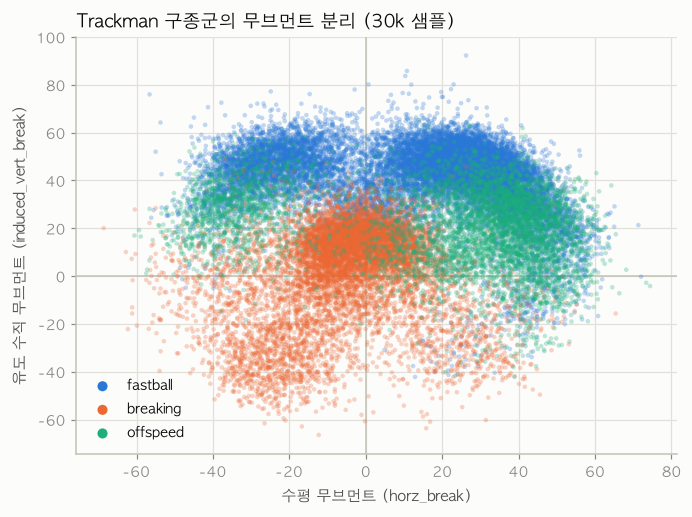

In [24]:
# 구종군별 물리량 — 상황 키로 붙일 수 있는 리그 평균 피처의 후보
pt = (tm.groupby("pitch_type_group")
        .agg(n=("trackman_id", "size"), rel_speed=("rel_speed", "mean"),
             spin_rate=("spin_rate", "mean"), induced_vert_break=("induced_vert_break", "mean"),
             horz_break=("horz_break", "mean"), extension=("extension", "mean"))
        .sort_values("n", ascending=False))
print(pt)

fig, ax = plt.subplots(figsize=(6.4, 4.8))
order = ["fastball", "breaking", "offspeed"]
colors = {"fastball": C1, "breaking": C2, "offspeed": C3}
samp = tm[tm.pitch_type_group.isin(order)].sample(30000, random_state=0)
for g_ in order:
    s = samp[samp.pitch_type_group == g_]
    ax.scatter(s.horz_break, s.induced_vert_break, s=9, alpha=0.28,
               color=colors[g_], edgecolor="none", label=g_, zorder=3)
ax.axhline(0, color=AXIS, lw=1.0); ax.axvline(0, color=AXIS, lw=1.0)
ax.set_xlabel("수평 무브먼트 (horz_break)"); ax.set_ylabel("유도 수직 무브먼트 (induced_vert_break)")
ax.set_title("Trackman 구종군의 무브먼트 분리 (30k 샘플)")
leg = ax.legend(loc="lower left", markerscale=2.2)
for h in leg.legend_handles: h.set_alpha(1.0)
plt.tight_layout(); plt.show()

`asof_pitcher_fastball_rate` / `breaking_rate` / `offspeed_rate` 는 이미 메인 데이터에 제공된다.
즉 **trackman의 구종 정보 중 쓸 만한 부분은 이미 요약되어 들어와 있다.**
남은 미사용 정보는 구속·회전수·무브먼트 같은 *물리량*인데, 이건 선수 ID 없이는 개인 단위로 붙일 수 없다.
→ **trackman은 후순위**. 먼저 메인 데이터를 짜내는 게 점수 대비 효율이 높다.

### 8. 주최측 베이스라인 진단

`baseline_submit/` 에 제공된 `rf.pkl` 이 실제로 무엇이고, 어디가 열려 있는지 직접 뜯어본다.
**베이스라인은 "돌아가는 제출 형식 예시"이지 성능 기준선이 아니다** — 이 절에서 그 이유를 확인한다.

In [25]:
import joblib, time
from sklearn.metrics import roc_auc_score

BASE = PROJECT_ROOT / "baseline_submit"
model = joblib.load(BASE / "model/rf.pkl")
clf = model.named_steps["clf"]

print("파이프라인 구조")
for name, trans, cols in model.named_steps["pre"].transformers_:
    print(f"  [{name:4s}] {type(trans).__name__:18s} {len(cols)}개 컬럼")
print(f"  [clf ] {type(clf).__name__}(n_estimators={clf.n_estimators}, "
      f"max_depth={clf.max_depth}, min_samples_leaf={clf.min_samples_leaf})")
print(f"\n총 입력 피처: {model.n_features_in_}개")
print((BASE / "requirements.txt").read_text())

파이프라인 구조
  [cat ] OrdinalEncoder     3개 컬럼
  [num ] SimpleImputer      44개 컬럼
  [clf ] RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=200)

총 입력 피처: 47개
scikit-learn==1.8.0
joblib==1.5.3
pandas==2.3.3



#### 8.1 🚨 이 모델은 2024년까지 전부 학습했다 — 정직한 기준선이 아니다

시즌별 예측 평균이 실제 성공률을 얼마나 따라가는지 보면 학습 범위가 드러난다.

In [26]:
X_all = train.drop(columns=[ID_COL, TARGET])
p_all = model.predict_proba(X_all)[:, 1]
train_pred = train[["season", TARGET]].copy()
train_pred["pred"] = p_all

diag = train_pred.groupby("season").agg(
    실제=(TARGET, "mean"), 예측평균=("pred", "mean"), 예측표준편차=("pred", "std")).reset_index()
diag["갭(%p)"] = (diag.예측평균 - diag.실제) * 100
diag["원점수"] = [bss_raw(g[TARGET], g.pred) for _, g in train_pred.groupby("season")]
diag

,season,실제,예측평균,예측표준편차,갭(%p),원점수
0,2019,0.5647,0.5578,0.0554,-0.6826,"2,304.6167"
1,2020,0.5327,0.5370,0.0422,0.4266,"1,204.6046"
2,2021,0.5328,0.5284,0.0525,-0.4377,"2,137.7679"
3,2022,0.5289,0.5256,0.0596,-0.3318,"2,532.0874"
4,2023,0.5000,0.5029,0.0363,0.2931,"1,178.4890"
5,2024,0.4861,0.4931,0.0356,0.7007,"1,153.1148"


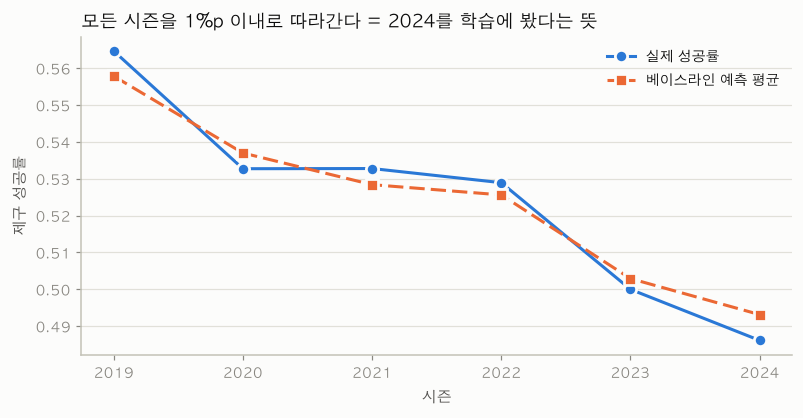

최대 절대 갭: 0.7 %p
→ 드리프트를 이만큼 따라간다는 것은 2024 데이터를 학습에 사용했다는 뜻.
→ 따라서 아래 2024 점수는 모두 in-sample이며 낙관적이다. 정직한 기준선이 되려면
   2019-2023만으로 동일 설정을 재학습해야 한다.


In [27]:
fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.plot(diag.season, diag.실제, color=C1, marker="o",
        markeredgecolor=SURFACE, markeredgewidth=1.8, label="실제 성공률", zorder=3)
ax.plot(diag.season, diag.예측평균, color=C2, marker="s", ls=(0, (5, 2)),
        markeredgecolor=SURFACE, markeredgewidth=1.8, label="베이스라인 예측 평균", zorder=4)
ax.set_title("모든 시즌을 1%p 이내로 따라간다 = 2024를 학습에 봤다는 뜻")
ax.set_xlabel("시즌"); ax.set_ylabel("제구 성공률"); ax.set_xticks(diag.season)
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print("최대 절대 갭:", round(diag["갭(%p)"].abs().max(), 2), "%p")
print("→ 드리프트를 이만큼 따라간다는 것은 2024 데이터를 학습에 사용했다는 뜻.")
print("→ 따라서 아래 2024 점수는 모두 in-sample이며 낙관적이다. 정직한 기준선이 되려면")
print("   2019-2023만으로 동일 설정을 재학습해야 한다.")

#### 8.2 베이스라인은 **과소 자신(under-dispersed)** — §6.2와 정반대 방향

날것 `asof_*` 피처는 과하게 퍼져 있어 **축소**가 필요했다. 학습된 RF는 그 반대다.

예측 확률  평균 0.4931 | 표준편차 0.0356 | 범위 0.3794~0.6201
실제 성공률 0.4861
AUC 0.5659   원점수(그대로) 1153.1


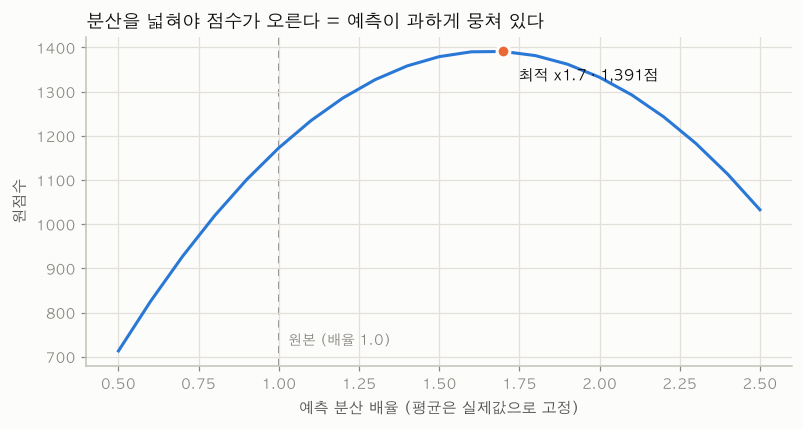

배율 1.0 → 1173점 대비 최적 x1.7 → 1391점


In [28]:
h = train[train.season == 2024]
y_h = h[TARGET].values
p_h = model.predict_proba(h.drop(columns=[ID_COL, TARGET]))[:, 1]

print(f"예측 확률  평균 {p_h.mean():.4f} | 표준편차 {p_h.std():.4f} | 범위 {p_h.min():.4f}~{p_h.max():.4f}")
print(f"실제 성공률 {y_h.mean():.4f}")
print(f"AUC {roc_auc_score(y_h, p_h):.4f}   원점수(그대로) {bss_raw(y_h, p_h):.1f}")

scales = np.arange(0.5, 2.6, 0.1)
sweep = [bss_raw(y_h, np.clip((p_h - p_h.mean()) * s + y_h.mean(), 1e-6, 1 - 1e-6)) for s in scales]
best_i = int(np.argmax(sweep))

fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(scales, sweep, color=C1, zorder=3)
ax.axvline(1.0, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.annotate("원본 (배율 1.0)", xy=(1.0, min(sweep)), xytext=(6, 4),
            textcoords="offset points", color=MUTED, fontsize=9)
ax.scatter([scales[best_i]], [sweep[best_i]], s=70, color=C2, zorder=5,
           edgecolor=SURFACE, linewidth=2)
ax.annotate(f"최적 x{scales[best_i]:.1f} · {sweep[best_i]:,.0f}점",
            xy=(scales[best_i], sweep[best_i]), xytext=(10, -10), textcoords="offset points",
            ha="left", va="top", fontsize=10, fontweight="bold", color=INK)
ax.set_xlabel("예측 분산 배율 (평균은 실제값으로 고정)"); ax.set_ylabel("원점수")
ax.set_title("분산을 넓혀야 점수가 오른다 = 예측이 과하게 뭉쳐 있다")
plt.tight_layout(); plt.show()

print(f"배율 1.0 → {sweep[list(scales).index(1.0) if 1.0 in list(scales) else 5]:.0f}점 대비 "
      f"최적 x{scales[best_i]:.1f} → {sweep[best_i]:.0f}점")

`max_depth=10` + `min_samples_leaf=200` 은 147만 행에 비해 지나치게 얕다.
잎마다 최소 200개를 평균 내니 예측이 전부 평균 근처로 뭉개진다 — 전형적인 **under-fitting**이다.
(배율 최적값 자체는 in-sample이라 그대로 믿을 수 없지만, **in-sample인데도 과소 자신**이라는
사실 자체가 under-fitting의 강한 증거다.)

#### 8.3 `season` 을 피처로 쓰는데 2025는 학습에 없는 값이다

In [29]:
X_t = test.drop(columns=[ID_COL])
for s in [2023, 2024, 2025, 2030, 2100]:
    X_s = X_t.copy(); X_s["season"] = s
    print(f"season={s:4d}:", np.round(model.predict_proba(X_s)[:, 1], 5))
print("\n→ 2025/2030/2100 예측이 2024와 완전히 동일하다.")
print("  트리는 마지막 분기점으로 고정할 뿐 추세를 외삽하지 않는다.")
print("  season은 추세를 외삽하지 않는다. 포함/제외는 시간 폴드에서 비교하고 드리프트 대응은 별도로 검증한다.")

season=2023: [0.46353 0.44949 0.48886 0.5074  0.49031]
season=2024: [0.46291 0.44757 0.4852  0.50627 0.48981]


season=2025: [0.46291 0.44757 0.4852  0.50627 0.48981]
season=2030: [0.46291 0.44757 0.4852  0.50627 0.48981]
season=2100: [0.46291 0.44757 0.4852  0.50627 0.48981]

→ 2025/2030/2100 예측이 2024와 완전히 동일하다.
  트리는 마지막 분기점으로 고정할 뿐 추세를 외삽하지 않는다.
  season은 추세를 외삽하지 않는다. 포함/제외는 시간 폴드에서 비교하고 드리프트 대응은 별도로 검증한다.


#### 8.4 `SimpleImputer(median)` 이 cold-start 신호를 지운다

In [30]:
# §4에서 확인한 '정보 있는 결측'이 median 대치로 사라진다
imp_cols = ["asof_pitcher_success_rate", "asof_batter_success_rate"]
for c in imp_cols:
    m_na = train[c].isna()
    print(f"{c}")
    print(f"   결측 {m_na.sum():>6,}행의 실제 성공률 {train.loc[m_na, TARGET].mean():.4f} "
          f"vs 비결측 {train.loc[~m_na, TARGET].mean():.4f} "
          f"(차이 {(train.loc[m_na, TARGET].mean()-train.loc[~m_na, TARGET].mean())*100:+.2f}%p)")
    print(f"   → median({train[c].median():.4f})으로 채우면 이 구분이 사라진다\n")

t0 = time.time(); model.predict_proba(X_all.iloc[:245789]); el = time.time() - t0
print(f"추론 속도: 245,789행에 {el:.2f}초 (제한 600초) — 여유 약 {600/el:,.0f}배")
print("→ 이 RF의 순수 predict 시간에는 여유가 있다. 최종 ZIP은 로딩·전처리까지 포함해 서버와 유사한 환경에서 다시 잰다.")

asof_pitcher_success_rate
   결측    792행의 실제 성공률 0.5518 vs 비결측 0.5238 (차이 +2.80%p)
   → median(0.5320)으로 채우면 이 구분이 사라진다

asof_batter_success_rate
   결측    830행의 실제 성공률 0.6024 vs 비결측 0.5237 (차이 +7.87%p)
   → median(0.5322)으로 채우면 이 구분이 사라진다



추론 속도: 245,789행에 0.34초 (제한 600초) — 여유 약 1,744배
→ 이 RF의 순수 predict 시간에는 여유가 있다. 최종 ZIP은 로딩·전처리까지 포함해 서버와 유사한 환경에서 다시 잰다.


#### 8.5 베이스라인 진단 요약

| 지점 | 현재 | 개선 방향 |
|---|---|---|
| 학습 범위 | 2024까지 포함 → 점수가 in-sample | **측정용**은 2019-2023 재학습, **제출용**은 2024 포함 (§9.1) |
| 캘리브레이션 | 과소 자신 (예측 표준편차 0.036) | 검증셋에서 **분산 확대** 배율 탐색 / isotonic |
| 모델 용량 | `depth=10, leaf=200` — under-fitting | LightGBM, 더 깊게 |
| 결측 처리 | `SimpleImputer(median)` — cold-start 신호 삭제 | **native NaN** 처리 + `is_cold_start` 플래그 |
| `season` | 2025 값을 넣어도 추세 외삽은 안 됨 | 시간 폴드에서 포함/제외 비교 + 최근 시즌 가중 실험 |
| 추론 시간 | RF 순수 예측 245k행 0.4초 | 용량 여지는 있으나 최종 ZIP 전체 실행을 재측정 |

### 9. 검증(CV) 전략

train은 2019~2024, test는 2025. **랜덤 KFold를 쓰면 리더보드와 괴리가 생긴다.**
- 랜덤 분할은 같은 경기의 투구가 train/valid에 섞여 낙관적 추정을 만든다.
- `asof_*` 는 시간 누적 피처라, 미래 행이 train에 들어가면 사실상 정보 누출이다.

→ **시즌 단위 forward-chaining(확장 윈도우) CV** 를 표준으로 삼는다.

In [31]:
folds = [
    (list(range(2019, 2021)), 2021),
    (list(range(2019, 2022)), 2022),
    (list(range(2019, 2023)), 2023),
    (list(range(2019, 2024)), 2024),
]
rows = []
for tr_s, va_s in folds:
    tr_m = train.season.isin(tr_s); va_m = train.season == va_s
    y_va = train.loc[va_m, TARGET]
    p_const = train.loc[tr_m, TARGET].mean()   # train 평균을 그대로 쓴 경우
    rows.append({
        "학습 시즌": f"{tr_s[0]}-{tr_s[-1]}", "검증 시즌": va_s,
        "학습 행수": int(tr_m.sum()), "검증 행수": int(va_m.sum()),
        "학습 성공률": p_const, "검증 성공률": y_va.mean(),
        "성공률 갭(%p)": (y_va.mean() - p_const) * 100,
    })
cv = pd.DataFrame(rows)
cv

,학습 시즌,검증 시즌,학습 행수,검증 행수,학습 성공률,검증 성공률,성공률 갭(%p)
0,2019-2020,2021,481500,247088,0.5485,0.5328,-1.5708
1,2019-2021,2022,728588,247472,0.5431,0.5289,-1.4222
2,2019-2022,2023,976060,245525,0.5395,0.5000,-3.9579
3,2019-2023,2024,1221585,253507,0.5316,0.4861,-4.5477


마지막 폴드(학습 2019-2023 → 검증 2024)가 **실제 대회 상황(과거 전부 → 다음 시즌)과 구조가 같다**.
로컬 실험은 이 폴드를 1순위 기준으로 삼고, 나머지 폴드는 안정성 확인용으로 쓴다.

`row_id`는 시간 정렬 키가 아니므로 분할에 사용하지 않는다. 현재 제공 컬럼만으로는 시즌 내 정확한 경기 순서를 복원할 수 없어서 **시즌 단위 폴드**를 표준으로 삼는다.

#### 9.1 ⚠️ "2024를 학습에서 뺀다"는 뜻이 아니다 — 측정과 제출을 분리한다

§8.1에서 주최측 베이스라인이 2024를 학습에 포함한 것을 지적했는데, 이건 **2024를 쓰지 말라는 뜻이 아니다.**
2024로 학습한 모델의 2024 점수를 성능 근거로 쓸 수 없다는 뜻일 뿐이다.

```
[측정 단계]  2019-2023 학습 → 2024 검증
             하이퍼파라미터 · 피처 · 보정 배율을 여기서 결정
                  ↓ 결정된 설정만 그대로 가져감
[제출 단계]  2019-2024 전부 학습 → 2025 예측
```

**측정 단계의 학습→검증 갭이 1시즌인데, 실제 제출의 학습(~2024)→평가(2025) 갭도 1시즌이다.**
구조가 같아야 검증 점수가 리더보드를 대변한다. 그리고 제출용 모델에서는
**가장 최근이자 2025와 가장 가까운 2024를 반드시 넣어야 한다.**

#### 9.2 최근 시즌을 빼면 얼마나 손해인가 — 직접 측정

동일한 모델로 학습 범위만 바꿔 2024를 예측한다. 드리프트가 있으니 **최신 시즌의 가치**가 클 것으로 예상된다.
(이 셀은 학습을 두 번 수행하므로 1~2분 걸린다.)

In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder

CAT = ["top_bottom", "game_type", "base_state"]
gbm_df = train.copy()
gbm_df[CAT] = OrdinalEncoder(handle_unknown="use_encoded_value",
                             unknown_value=-1).fit_transform(gbm_df[CAT].astype(str))
# 이 절제 실험에서는 season을 제외한다. 포함/제외 비교는 별도 시간 폴드 실험으로 판단한다.
GBM_FEATS = [c for c in gbm_df.columns if c not in (ID_COL, TARGET, "season")]

def fit_predict(train_seasons, valid_season):
    a = gbm_df[gbm_df.season.isin(train_seasons)]
    b = gbm_df[gbm_df.season == valid_season]
    m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06, max_leaf_nodes=63,
                                       min_samples_leaf=200, random_state=42,
                                       early_stopping=False)
    m.fit(a[GBM_FEATS], a[TARGET])
    return m.predict_proba(b[GBM_FEATS])[:, 1], b[TARGET].values

rows = []
for label, seasons in [("2019-2022 (2년 갭)", list(range(2019, 2023))),
                       ("2019-2023 (1년 갭)", list(range(2019, 2024)))]:
    p, y = fit_predict(seasons, 2024)
    rows.append({"학습 범위": label, "예측 평균": p.mean(), "실제 평균": y.mean(),
                 "원점수": bss_raw(y, p)})
    if seasons[-1] == 2023:
        p_best, y_best = p, y      # 아래 배율 스윕에 재사용
recency = pd.DataFrame(rows)
recency

,학습 범위,예측 평균,실제 평균,원점수
0,2019-2022 (2년 갭),0.5198,0.4861,"-1,747.7412"
1,2019-2023 (1년 갭),0.5075,0.4861,42.6961


**직전 시즌 하나를 넣고 빼는 것만으로 점수가 1,700점 넘게 움직인다.**
오래된 시즌만으로 학습하면 확률 수준이 과거에 묶여 원점수가 크게 음수가 된다.
2025 예측에서 2024는 가장 가깝고 가장 값진 시즌이므로, **제출 모델에서 빼는 것은 자해다.**

#### 9.3 Oracle 캘리브레이션 진단 — 실제 모델 점수와 구분

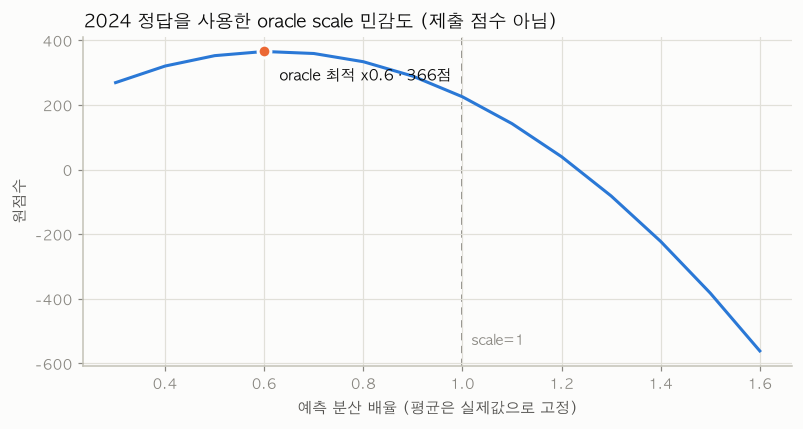

예측 표준편차 0.0490 | 원본 42.7점 → oracle 최적 x0.6 365.6점 (정직한 검증 점수 아님)


In [33]:
# 주의: 2024 정답 평균과 정답 점수로 scale을 고르므로 oracle 진단이다.
# 실제 캘리브레이터/scale은 더 과거 폴드의 OOF 예측으로만 학습해야 한다.
scales = np.arange(0.3, 1.7, 0.1)
sweep_gbm = [bss_raw(y_best, np.clip((p_best - p_best.mean()) * s + y_best.mean(), 1e-6, 1 - 1e-6))
             for s in scales]
bi = int(np.argmax(sweep_gbm))

fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(scales, sweep_gbm, color=C1, zorder=3)
ax.axvline(1.0, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.annotate("scale=1", xy=(1.0, min(sweep_gbm)), xytext=(6, 4),
            textcoords="offset points", color=MUTED, fontsize=9)
ax.scatter([scales[bi]], [sweep_gbm[bi]], s=70, color=C2, zorder=5,
           edgecolor=SURFACE, linewidth=2)
ax.annotate(f"oracle 최적 x{scales[bi]:.1f} · {sweep_gbm[bi]:,.0f}점",
            xy=(scales[bi], sweep_gbm[bi]), xytext=(10, -10), textcoords="offset points",
            ha="left", va="top", fontsize=10, fontweight="bold", color=INK)
ax.set_xlabel("예측 분산 배율 (평균은 실제값으로 고정)"); ax.set_ylabel("원점수")
ax.set_title("2024 정답을 사용한 oracle scale 민감도 (제출 점수 아님)")
plt.tight_layout(); plt.show()

print(f"예측 표준편차 {p_best.std():.4f} | 원본 {bss_raw(y_best, p_best):.1f}점 "
      f"→ oracle 최적 x{scales[bi]:.1f} {sweep_gbm[bi]:.1f}점 (정직한 검증 점수 아님)")

아래 scale은 모두 같은 데이터의 정답을 보고 고른 **oracle 진단값**이다. 실제 모델 선택 점수로 사용하면 누출이다. 다만 대상마다 민감도 방향이 다르다는 사실은 확인할 수 있다.

| 대상 | 성질 | oracle 최적 배율 |
|---|---|---|
| 날것 `asof_*` 피처 (§6.2) | 과신 (표본 부족) | **축소** 0.3배 |
| 베이스라인 RF, 얕음 (§8.2) | 과소 자신 (under-fitting) | **확대** 1.7배 |
| GBM, 깊음 (§9.3) | 과신 (over-fitting) | **축소** 0.6배 |

**모델 구성을 바꿀 때마다 과거 OOF 예측에서만 배율/보정기를 학습**하고 다음 시즌에 그대로 적용해야 한다.

또 하나: 정직하게 측정한 GBM의 원점수는 수십 점대다. oracle 보정 후 수백 점대 수치는 제출 가능 성능으로 해석하지 않는다.
§8의 베이스라인 1,153점은 in-sample이라 부풀려진 값이었다.
**Public 커트라인 549.51점은 결코 만만한 수치가 아니다.**

#### 9.4 과거 base rate 추세 — 민감도 진단 전용

In [34]:
rows = []
for label, d in [("정규경기(R)만", train[train.game_type == "R"]), ("전체", train)]:
    s = d.groupby("season")[TARGET].mean()
    dl = s.diff().dropna()
    rows.append({"대상": label, "2023": s.loc[2023], "2024": s.loc[2024],
                 "연간변화(전체평균)": dl.mean(), "연간변화(최근3년)": dl.tail(3).mean(),
                 "2025 추정(추세)": s.iloc[-1] + dl.tail(3).mean(),
                 "2025 추정(2024유지)": s.iloc[-1]})
est = pd.DataFrame(rows)
print(est.to_string(index=False))
print()
print("→ 과거 추세의 크기를 보는 진단표다. 이 값에 test 전체 예측 평균을 맞추지 않는다.")
print("  최종 보정은 train의 시간 OOF에서 학습한 고정 함수만 행별 예측에 적용한다.")

      대상   2023   2024  연간변화(전체평균)  연간변화(최근3년)  2025 추정(추세)  2025 추정(2024유지)
정규경기(R)만 0.5031 0.4897     -0.0120     -0.0077       0.4820           0.4897
      전체 0.5000 0.4861     -0.0157     -0.0156       0.4706           0.4861

→ 과거 추세의 크기를 보는 진단표다. 이 값에 test 전체 예측 평균을 맞추지 않는다.
  최종 보정은 train의 시간 OOF에서 학습한 고정 함수만 행별 예측에 적용한다.


> **주의**: 2025 base rate는 알 수 없다. test의 `pred.mean()`을 특정 값으로 옮기는 방식은 다른 test 행의 정보를 사용하므로 적용하지 않는다.
> 드리프트는 최근 시즌 가중치·학습 구간·모델 intercept처럼 **train과 과거 시간 폴드에서 미리 고정되는 방법**으로만 대응한다. 리더보드 피드백으로 보정 상수를 맞추는 것도 하지 않는다.

### 10. 요약 및 다음 단계

#### 확인된 사실
| # | 발견 | 근거 |
|---|---|---|
| 1 | **train 2019-2024 / test 2025 — 시간 분할.** 랜덤 KFold 금지 | §3 |
| 2 | **타깃 base rate 하락** (56.5% → 48.6%, 한 시즌은 보합). 시간 드리프트가 핵심 리스크 | §3.1 |
| 3 | **Brier는 판별력과 캘리브레이션을 함께 평가**한다. AUC만으로 모델을 고르면 안 됨 | §6.2 |
| 3b | 정답 평균을 쓴 shift/scale은 **oracle 진단**일 뿐 정직한 모델 성능이 아님 | §6.2, §9.3 |
| 3c | **주최측 베이스라인은 2024까지 학습** → 제공된 점수는 기준선으로 쓸 수 없다 | §8.1 |
| 3d | 단 **제출 모델에는 2024를 반드시 포함**한다 — 직전 시즌 유무가 1,700점 이상 좌우 | §9.1-9.2 |
| 4 | **`game_type=F`(11%)는 성격이 다른 데이터** — 시즌별 성공률 0.46~0.71로 요동 | §5.3 |
| 5 | 볼카운트가 두 번째 신호. 단 **스트라이크 방향은 비단조** (0-1 최고, 0-2는 평균 이하) | §5.1 |
| 6 | 개별 피처의 **선형 신호가 약하다** — 최대 Pearson 상관 0.084. 비선형·상호작용은 별도 검증 | §6.1 |
| 7 | 투수 능력은 지속되나 **평균회귀**(기울기 0.65) → shrinkage 필요 | §6.3 |
| 7b | `asof_pitcher_n`은 **다른 피처의 신뢰도 게이트** — 50구 미만은 극단값, 10k+는 폼 미반영 | §6.4 |
| 8 | 결측은 `asof_*` 에만, **표본 0인 cold-start** = 정보 있는 결측 | §4 |
| 9 | **trackman은 선수 ID 교집합 0명 → 직접 조인 불가**. 익명 ID 역추정은 하지 않음 | §7 |
| 10 | 타깃은 거의 균형 (52.4%) — 불균형 처리 불필요 | §2 |
| 11 | BSS ×100000 → **0.1%p 개선이 100점**, 커트라인은 BSS 0.0055 | §1 |

#### 다음 단계 (우선순위)
1. **2단계 프로토콜을 고정한다**(§9.1) — 측정은 2019-2023 학습 / 2024 검증,
   제출은 **2019-2024 전부 학습**. 주최측 `rf.pkl` 점수는 in-sample이라 비교 대상이 아니므로,
   같은 설정을 측정 모드로 재학습해 정직한 기준 숫자를 먼저 확보한다.
2. **OOF 캘리브레이션** — 모델별 시간 OOF 예측으로만 scale/Platt/isotonic을 학습하고 다음 시즌에 고정 적용한다. 현재 검증 시즌의 정답 평균을 쓰거나 test의 예측 평균을 사후 이동하지 않는다.
3. **모델 교체** — LightGBM부터 시작해 CatBoost/XGBoost와 비교한다. native NaN 처리를 쓰고 결측을 대치하지 않는다. 최종 ZIP의 모델 로딩·전처리·추론 전체가 10분 안인지 다시 측정한다.
4. **`game_type` 실험** — F 제외 / 가중치 축소 / 피처로 유지 3안을 2024 홀드아웃(R 한정)에서 비교.
5. **드리프트 대응** — 최근 시즌 sample weight와 학습 window를 비교한다. `season`은 추세를 외삽하지 않으므로 시간 폴드에서 포함/제외를 실험한다.
6. **파생 피처** — 카운트 12종 범주형, `is_cold_start` 플래그,
   `asof_pitcher_success_rate` 의 `asof_pitcher_n` 가중 shrinkage,
   최근 경기 성공률 − 통산 성공률(폼), 투수×타자 손 매치업.
7. **제출 파이프라인** — `baseline_submit/script.py` 구조 유지(실행 검증 완료),
   오프라인 실행 가능하도록 모델 파일 동봉.
8. (후순위) **trackman** — 상황 키 기반 리그 평균 물리량 결합의 실익 측정. 기대값 낮음.